In [3]:
import numpy as np 
import matplotlib.pyplot as plt

In [4]:
# Vamos criar nossos dados sintéticos como passado em sala
N = 12
M = 9
real_data = np.empty((3,3))
real_data[:,0] = 1
real_data[:,1] = 1, 5, 1
real_data[:,2] = 1

dist = 1
diag = dist * np.sqrt(2)

true_p = np.ones(9)
true_p[4] = 4

print(true_p)

[1. 1. 1. 1. 4. 1. 1. 1. 1.]


In [5]:
# Equações do problema:
# Horizontais
eq_1 = real_data[2,0] * dist + real_data[2,1] * dist + real_data[2,2] * dist
eq_2 = real_data[1,0] * dist + real_data[1,1] * dist + real_data[1,2] * dist
eq_3 = real_data[0,0] * dist + real_data[0,1] * dist + real_data[0,2] * dist
# Verticais
eq_4 = real_data[0,0] * dist + real_data[1,0] * dist + real_data[2,0] * dist
eq_5 = real_data[0,1] * dist + real_data[1,1] * dist + real_data[2,1] * dist
eq_6 = real_data[0,2] * dist + real_data[1,2] * dist + real_data[2,2] * dist
# Diagonais
eq_7 = real_data[2,2] * diag
eq_8 = real_data[2,1] * diag + real_data[1,2] * diag
eq_9 = real_data[2,0] * diag + real_data[1,1] * diag + real_data[0,2] * diag
eq_10 = real_data[0,1] * diag + real_data[0,1] * diag
eq_11 = real_data[0,0] * diag
eq_12 = real_data[0,0] * diag + real_data[1,1] * diag + real_data[2,2] * diag

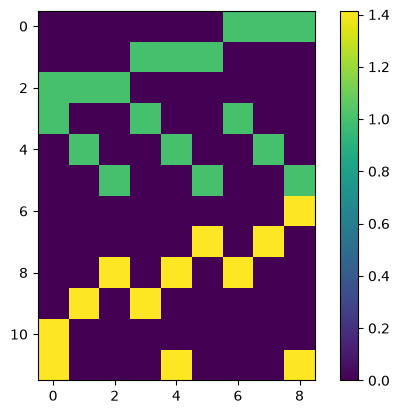

In [6]:
# Vamos construir nossa matriz jacobiana 
G = np.zeros((N,M))
# Equações Horizontais
G[0, [6, 7, 8]] = dist      # eq_1: p7 + p8 + p9
G[1, [3, 4, 5]] = dist      # eq_2: p4 + p5 + p6
G[2, [0, 1, 2]] = dist      # eq_3: p1 + p2 + p3
# Equações Verticais
G[3, [0, 3, 6]] = dist      # eq_4: p1 + p4 + p7
G[4, [1, 4, 7]] = dist      # eq_5: p2 + p5 + p8
G[5, [2, 5, 8]] = dist      # eq_6: p3 + p6 + p9
# Equações Diagonais
G[6, [-1]]       = diag      # eq_7: p9
G[7, [5, 7]]    = diag      # eq_8: p6 + p8
G[8, [2, 4, 6]] = diag      # eq_9: p3 + p5 + p7
G[9, [1, 3]]    = diag      # eq_10: p2 + p4
G[10, [0]]      = diag      # eq_11: p1
G[11, [0, 4, 8]]= diag      # eq_12: p1 + p5 + p9
#G[12, [6]] = diag
#G[13, [3,7]] = diag
#G[14, [1,5]] = diag
#G[15,[2]] = diag
plt.imshow(G)
plt.colorbar()

In [21]:
# Vetor de observações 
#y = np.array([eq_1, eq_2, eq_3, eq_4, eq_5, eq_6,eq_7, eq_8, eq_9, eq_10, eq_11, eq_12])
data = G @ true_p
data += np.random.default_rng().normal(0, 0.01 * np.abs(data).max(), data.shape)
# Estimativa por mínimos quadrados
p_est = np.linalg.solve(G.T @ G, G.T @ data)
# Reconverte o vetor estimado para a grade 3x3 original
p_grid = p_est.reshape((3, 3))
# Printa o resultado
p_grid

array([[1.03685981, 1.20435035, 0.74729614],
       [0.73433332, 4.02716809, 1.28489137],
       [1.2779104 , 0.71793126, 1.02574577]])

# Análise de SVD e solução por pseudo-inversão

In [ ]:
U, S, Vt = np.linalg.svd(G)
# Se os valores singulares de S forem igual a 0 ou muito proximo de 0 entramos 
# em um espaço nulo 
S

array([3.62258273e+00, 2.44948974e+00, 2.44948974e+00, 2.20836917e+00,
       1.73205081e+00, 1.73205081e+00, 1.73205081e+00, 1.73205081e+00,
       1.92239241e-16])

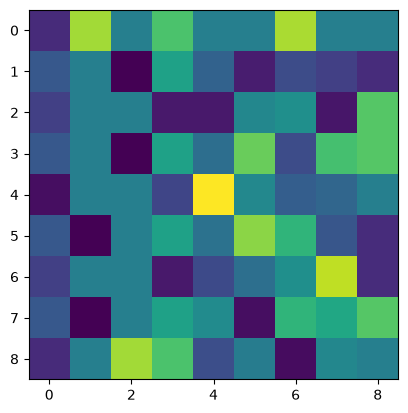

In [23]:
plt.imshow(Vt.T)

In [26]:
data = G @ true_p
data += np.random.default_rng().normal(0, 0.01 * np.abs(data).max(), data.shape)
#Solução por SVD
U, S, Vt = np.linalg.svd(G)
k = S.size - 1 
Sp = np.diag(S[:k])
Up = U[:, :k]
Vp = Vt.T[:, :k]
print(np.shape(Sp))
print(np.shape(Up))
print(np.shape(Vp))
# Estimativa de minimos quadrados com a pseudo inversa de Moore Penrose
p_pseudo = Vp @ np.linalg.inv(Sp) @ Up.T @ data
p_pseudo.reshape((3,3))

(8, 8)
(12, 8)
(9, 8)


array([[1.01764242, 1.04463831, 1.00842724],
       [1.01461612, 3.96705133, 0.97212148],
       [1.04825938, 1.04197581, 0.95571926]])